# Laboratório — Aula 2 (execução própria)
**Henrique Ribeiro Leonardo** · Sistemas de Informação · UDF · Profa. Kadidja Valéria · 2026.2

Execução individual do laboratório do Módulo IV. Parti do notebook didático da professora, mas fiz algumas escolhas diferentes:

- carrego o **CSV fornecido** (`dados/educacionais-sinteticos.csv`) em vez de regenerar os dados;
- a busca de parâmetros cruza `max_depth` **e** `min_samples_leaf` **antes** de tocar no teste (exercício 1 do notebook feito na ordem certa);
- além da acurácia, registro precisão, F1 e um **limiar de decisão** escolhido só com o treino;
- na regressão, comparo atributos por validação cruzada e mostro o efeito da extrapolação.

Todos os dados são **sintéticos**. As relações foram definidas pela simulação e não dizem nada sobre estudantes reais.

In [1]:
import sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold,
                                     cross_validate, cross_val_predict)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score,
                             mean_absolute_error, r2_score)
SEMENTE = 42
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__, '| pandas:', pd.__version__,
      '| matplotlib:', plt.matplotlib.__version__, '| scikit-learn:', sklearn.__version__)

Python: 3.13.18
NumPy: 2.5.3 | pandas: 3.0.5 | matplotlib: 3.11.2 | scikit-learn: 1.9.1


## 1. Dados
Unidade de análise: um estudante fictício. Momento da previsão: **fim da semana 4**. Atributos conhecidos nesse momento: frequência (%), nota parcial (0–10) e entregas (0–8). Alvo: `evasao_fim_semestre` (1 = evadiu), só conhecido no fim do semestre.

In [2]:
dados = pd.read_csv('../dados/educacionais-sinteticos.csv')
print('Dimensões:', dados.shape)
print(dados.describe().round(2).to_string())
print('\nAusentes por coluna:'); print(dados.isna().sum().to_string())
print('\nClasses (%):'); print(dados['evasao_fim_semestre'].value_counts(normalize=True).mul(100).round(1).to_string())

Dimensões: (600, 4)
       frequencia_sem4  nota_sem4  entregas_sem4  evasao_fim_semestre
count           600.00     570.00         600.00               600.00
mean             67.24       5.06           4.02                 0.41
std              18.67       2.94           2.63                 0.49
min              35.35       0.01           0.00                 0.00
25%              50.39       2.48           2.00                 0.00
50%              67.49       4.96           4.00                 0.00
75%              83.77       7.64           6.00                 1.00
max              99.94       9.99           8.00                 1.00

Ausentes por coluna:
frequencia_sem4         0
nota_sem4              30
entregas_sem4           0
evasao_fim_semestre     0

Classes (%):
evasao_fim_semestre
0    59.0
1    41.0


## 2. Divisão antes de qualquer transformação
Holdout estratificado 75/25. Os registros simulados são independentes, então a divisão aleatória é aceitável aqui. Com turmas reais, eu treinaria em semestres passados e testaria no semestre seguinte.

In [3]:
atributos = ['frequencia_sem4', 'nota_sem4', 'entregas_sem4']
X, y = dados[atributos], dados['evasao_fim_semestre']
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEMENTE)
print('Treino:', len(X_treino), '| Teste:', len(X_teste))
print('Proporção de evasão — treino: %.3f | teste: %.3f' % (y_treino.mean(), y_teste.mean()))

Treino: 450 | Teste: 150
Proporção de evasão — treino: 0.411 | teste: 0.407


## 3. Escolha de parâmetros só no treino
Grade completa `max_depth` × `min_samples_leaf`, validação cruzada estratificada em 5 partes. Critério: maior acurácia média de validação; em empate técnico (diferença menor que 0,005), fico com a árvore mais simples.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
def arvore(prof, folha):
    return Pipeline([('imputador', SimpleImputer(strategy='median')),
                     ('arvore', DecisionTreeClassifier(max_depth=prof, min_samples_leaf=folha,
                                                       random_state=SEMENTE))])
linhas = []
for prof in [2, 3, 4, 5, 6, None]:
    for folha in [5, 10, 20, 40]:
        s = cross_validate(arvore(prof, folha), X_treino, y_treino, cv=cv,
                           scoring='accuracy', return_train_score=True)
        linhas.append({'max_depth': str(prof), 'min_samples_leaf': folha,
                       'treino': s['train_score'].mean(),
                       'validacao': s['test_score'].mean(),
                       'desvio': s['test_score'].std()})
grade = pd.DataFrame(linhas)
grade['distancia'] = grade['treino'] - grade['validacao']
print(grade.round(4).to_string(index=False))

max_depth  min_samples_leaf  treino  validacao  desvio  distancia
        2                 5  0.7328     0.6844  0.0425     0.0483
        2                10  0.7328     0.6844  0.0425     0.0483
        2                20  0.7328     0.6844  0.0425     0.0483
        2                40  0.7328     0.6844  0.0425     0.0483
        3                 5  0.7706     0.7000  0.0233     0.0706
        3                10  0.7678     0.7022  0.0257     0.0656
        3                20  0.7656     0.6978  0.0325     0.0678
        3                40  0.7661     0.7111  0.0351     0.0550
        4                 5  0.8050     0.7133  0.0333     0.0917
        4                10  0.7994     0.7244  0.0406     0.0750
        4                20  0.7828     0.7244  0.0504     0.0583
        4                40  0.7756     0.7289  0.0303     0.0467
        5                 5  0.8261     0.7222  0.0298     0.1039
        5                10  0.8111     0.7222  0.0391     0.0889
        5 

Configurações em empate técnico:
max_depth  min_samples_leaf  treino  validacao  desvio  distancia
        4                10  0.7994     0.7244  0.0406     0.0750
        4                20  0.7828     0.7244  0.0504     0.0583
        4                40  0.7756     0.7289  0.0303     0.0467
        5                20  0.7900     0.7267  0.0480     0.0633
        5                40  0.7756     0.7289  0.0303     0.0467
        6                20  0.7900     0.7267  0.0480     0.0633
        6                40  0.7756     0.7289  0.0303     0.0467
     None                20  0.7900     0.7267  0.0480     0.0633
     None                40  0.7756     0.7289  0.0303     0.0467

Escolhida: max_depth=4, min_samples_leaf=40


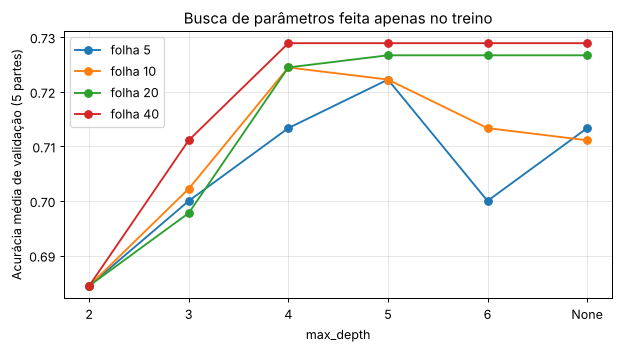

In [5]:
melhor_val = grade['validacao'].max()
empatados = grade[grade['validacao'] >= melhor_val - 0.005].copy()
# mais simples = menor profundidade (None conta como a mais complexa) e folhas maiores
empatados['prof_num'] = empatados['max_depth'].replace('None', '99').astype(int)
escolha = empatados.sort_values(['prof_num', 'min_samples_leaf'], ascending=[True, False]).iloc[0]
PROF = None if escolha['max_depth'] == 'None' else int(escolha['max_depth'])
FOLHA = int(escolha['min_samples_leaf'])
print('Configurações em empate técnico:'); print(empatados.drop(columns='prof_num').round(4).to_string(index=False))
print(f'\nEscolhida: max_depth={PROF}, min_samples_leaf={FOLHA}')

fig, ax = plt.subplots(figsize=(7, 4))
for folha in [5, 10, 20, 40]:
    g = grade[grade['min_samples_leaf'] == folha]
    ax.plot(g['max_depth'], g['validacao'], marker='o', label=f'folha {folha}')
ax.set_xlabel('max_depth'); ax.set_ylabel('Acurácia média de validação (5 partes)')
ax.set_title('Busca de parâmetros feita apenas no treino'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig('../assets/henrique-grade-validacao.png', dpi=110); plt.show()

## 4. Limiar de decisão (ainda só no treino)
O custo maior aqui é o **falso negativo** (estudante que evade sem receber convite). Em vez de usar o limiar padrão de 0,5, uso previsões fora da dobra (`cross_val_predict`) no treino para ver a troca entre sensibilidade e falsos positivos e fixo um limiar **antes** de olhar o teste.

In [6]:
modelo = arvore(PROF, FOLHA)
proba_oof = cross_val_predict(modelo, X_treino, y_treino, cv=cv, method='predict_proba')[:, 1]
tab = []
for lim in [0.3, 0.4, 0.5, 0.6]:
    p = (proba_oof >= lim).astype(int)
    tab.append({'limiar': lim, 'acuracia': accuracy_score(y_treino, p),
                'sensibilidade': recall_score(y_treino, p), 'precisao': precision_score(y_treino, p),
                'sinalizados_%': p.mean() * 100})
tab = pd.DataFrame(tab)
print(tab.round(3).to_string(index=False))
# regra definida antes do teste: menor limiar que mantém precisão >= 0,65
ok = tab[tab['precisao'] >= 0.65]
LIMIAR = float(ok['limiar'].min()) if len(ok) else 0.5
print(f'\nLimiar escolhido no treino: {LIMIAR}')

 limiar  acuracia  sensibilidade  precisao  sinalizados_%
    0.3     0.700          0.854     0.594         59.111
    0.4     0.711          0.746     0.624         49.111
    0.5     0.729          0.605     0.696         35.778
    0.6     0.729          0.605     0.696         35.778

Limiar escolhido no treino: 0.5


## 5. Avaliação final no teste (usado uma única vez)

In [7]:
modelo.fit(X_treino, y_treino)
base = DummyClassifier(strategy='most_frequent').fit(X_treino, y_treino)
proba_teste = modelo.predict_proba(X_teste)[:, 1]
res = {}
for nome, lim in sorted({('limiar_0.5', 0.5), (f'limiar_{LIMIAR}', LIMIAR)}):
    p = (proba_teste >= lim).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_teste, p, labels=[0, 1]).ravel()
    res[nome] = dict(acuracia=accuracy_score(y_teste, p), sensibilidade=recall_score(y_teste, p),
                     precisao=precision_score(y_teste, p), f1=f1_score(y_teste, p),
                     TN=int(tn), FP=int(fp), FN=int(fn), TP=int(tp))
acc_treino = modelo.score(X_treino, y_treino)
acc_base = accuracy_score(y_teste, base.predict(X_teste))
print(f'Acurácia de treino (modelo final): {acc_treino:.4f}')
print(f'Referência (sempre 0) no teste: {acc_base:.4f}')
print(pd.DataFrame(res).T.round(4).to_string())

Acurácia de treino (modelo final): 0.7622
Referência (sempre 0) no teste: 0.5933
            acuracia  sensibilidade  precisao      f1    TN    FP    FN    TP
limiar_0.5      0.78         0.7705    0.7121  0.7402  70.0  19.0  14.0  47.0


Primeira pergunta: nota_sem4 <= 6.21
Importâncias: {'frequencia_sem4': 0.21, 'nota_sem4': 0.7, 'entregas_sem4': 0.09}
Folhas: 8 | Profundidade real: 4


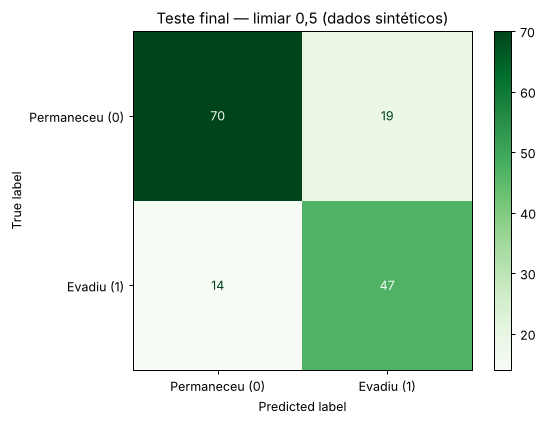

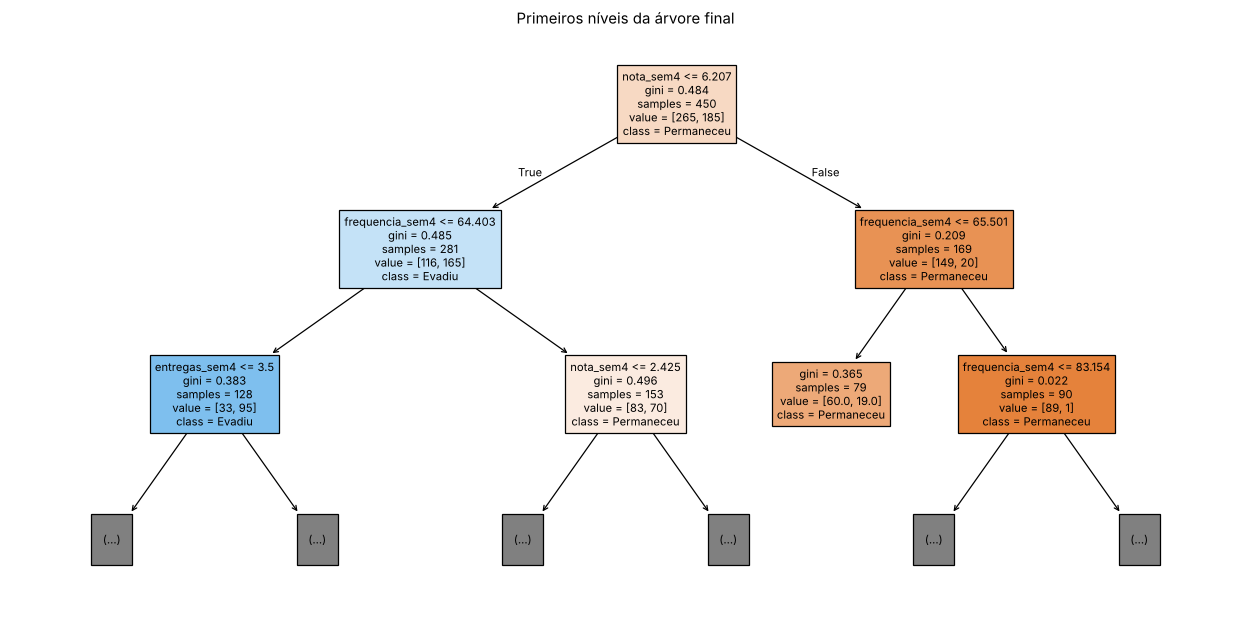

In [8]:
cm = confusion_matrix(y_teste, modelo.predict(X_teste), labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=['Permaneceu (0)', 'Evadiu (1)']).plot(cmap='Greens')
plt.title('Teste final — limiar 0,5 (dados sintéticos)'); plt.tight_layout()
plt.savefig('../assets/henrique-matriz-confusao.png', dpi=110); plt.show()

plt.figure(figsize=(14, 7))
plot_tree(modelo.named_steps['arvore'], feature_names=atributos,
          class_names=['Permaneceu', 'Evadiu'], max_depth=2, filled=True, fontsize=9)
plt.title('Primeiros níveis da árvore final'); plt.tight_layout()
plt.savefig('../assets/henrique-arvore.png', dpi=100); plt.show()
arv = modelo.named_steps['arvore']
print('Primeira pergunta:', atributos[arv.tree_.feature[0]], '<=', round(arv.tree_.threshold[0], 2))
print('Importâncias:', {a: round(float(v), 3) for a, v in zip(atributos, arv.feature_importances_)})
print('Folhas:', arv.get_n_leaves(), '| Profundidade real:', arv.get_depth())

## 6. Experimento: retirar um atributo (validação cruzada no treino)

In [9]:
abl = []
for fora in [None] + atributos:
    cols = [a for a in atributos if a != fora]
    s = cross_validate(arvore(PROF, FOLHA), X_treino[cols], y_treino, cv=cv, scoring='accuracy')
    abl.append({'sem': fora or '(nenhum)', 'validacao': s['test_score'].mean(), 'desvio': s['test_score'].std()})
abl = pd.DataFrame(abl); print(abl.round(4).to_string(index=False))

            sem  validacao  desvio
       (nenhum)     0.7289  0.0303
frequencia_sem4     0.7311  0.0333
      nota_sem4     0.6511  0.0303
  entregas_sem4     0.7244  0.0394


## 7. Regressão — demanda da biblioteca
Mesma simulação do notebook didático (300 semanas, semente 42). Alvo: empréstimos por semana.

In [10]:
rng_reg = np.random.default_rng(SEMENTE)
reg = pd.DataFrame({'usuarios_ativos': rng_reg.uniform(100, 1000, 300),
                    'horas_abertura': rng_reg.uniform(20, 60, 300)})
reg['emprestimos_semana'] = (30 + 0.35*reg['usuarios_ativos'] +
                             2.5*reg['horas_abertura'] + rng_reg.normal(0, 35, 300))
Xr, yr = reg[['usuarios_ativos', 'horas_abertura']], reg['emprestimos_semana']
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.25, random_state=SEMENTE)

kf = KFold(n_splits=5, shuffle=True, random_state=SEMENTE)
comp = []
for cols in [['usuarios_ativos', 'horas_abertura'], ['usuarios_ativos'], ['horas_abertura']]:
    s = cross_validate(LinearRegression(), Xr_tr[cols], yr_tr, cv=kf,
                       scoring=('neg_mean_absolute_error', 'r2'))
    comp.append({'atributos': ' + '.join(cols), 'MAE_val': -s['test_neg_mean_absolute_error'].mean(),
                 'R2_val': s['test_r2'].mean()})
print('Comparação no treino (validação cruzada 5 partes):')
print(pd.DataFrame(comp).round(3).to_string(index=False))

Comparação no treino (validação cruzada 5 partes):
                       atributos  MAE_val  R2_val
usuarios_ativos + horas_abertura   28.892   0.867
                 usuarios_ativos   35.904   0.798
                  horas_abertura   83.728   0.048


MAE teste: 28.59 | MAE referência: 84.73 | R² teste: 0.8774
Coeficientes: {'usuarios_ativos': 0.348, 'horas_abertura': 2.297} | intercepto: 37.32

Cinco primeiros registros do teste:
       real  previsto  erro_abs
203  208.90    209.40      0.50
266  277.71    277.32      0.39
152  190.95    227.18     36.23
9    229.67    271.95     42.29
233  359.77    363.62      3.85

Resíduos: média -1.28, desvio 35.47, mín -87.2, máx 64.6
Erros acima de 50 empréstimos: 12 de 75


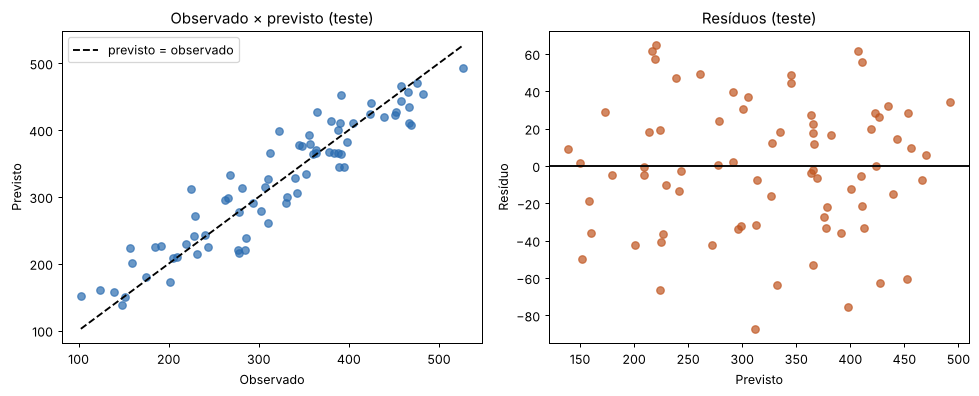

In [11]:
regressor = Pipeline([('imputador', SimpleImputer(strategy='median')), ('linear', LinearRegression())])
regressor.fit(Xr_tr, yr_tr)
pr = regressor.predict(Xr_te)
ref = DummyRegressor(strategy='mean').fit(Xr_tr, yr_tr)
mae, r2 = mean_absolute_error(yr_te, pr), r2_score(yr_te, pr)
mae_ref = mean_absolute_error(yr_te, ref.predict(Xr_te))
lin = regressor.named_steps['linear']
print(f'MAE teste: {mae:.2f} | MAE referência: {mae_ref:.2f} | R² teste: {r2:.4f}')
print('Coeficientes:', {c: round(float(v), 3) for c, v in zip(Xr.columns, lin.coef_)}, '| intercepto:', round(float(lin.intercept_), 2))
print('\nCinco primeiros registros do teste:')
print(pd.DataFrame({'real': yr_te, 'previsto': pr, 'erro_abs': np.abs(yr_te - pr)}).head().round(2).to_string())
residuos = yr_te - pr
print(f'\nResíduos: média {residuos.mean():.2f}, desvio {residuos.std():.2f}, mín {residuos.min():.1f}, máx {residuos.max():.1f}')
print(f'Erros acima de 50 empréstimos: {(np.abs(residuos) > 50).sum()} de {len(residuos)}')

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(yr_te, pr, alpha=.7, color='#2b6cb0')
lim = [min(yr_te.min(), pr.min()), max(yr_te.max(), pr.max())]
ax[0].plot(lim, lim, 'k--', label='previsto = observado'); ax[0].legend()
ax[0].set_xlabel('Observado'); ax[0].set_ylabel('Previsto'); ax[0].set_title('Observado × previsto (teste)')
ax[1].scatter(pr, residuos, alpha=.7, color='#c05621'); ax[1].axhline(0, color='k')
ax[1].set_xlabel('Previsto'); ax[1].set_ylabel('Resíduo'); ax[1].set_title('Resíduos (teste)')
plt.tight_layout(); plt.savefig('../assets/henrique-regressao.png', dpi=110); plt.show()

### Extrapolação
O modelo só viu 100–1000 usuários e 20–60 horas. Abaixo, o que ele "responde" fora desse domínio — a conta sai, mas nada garante que a relação continue linear.

In [12]:
fora = pd.DataFrame({'usuarios_ativos': [500, 1000, 5000, 10000], 'horas_abertura': [40, 60, 60, 100]})
fora['previsto'] = regressor.predict(fora).round(1)
fora['dentro_do_dominio'] = (fora['usuarios_ativos'].between(100, 1000) & fora['horas_abertura'].between(20, 60))
print(fora.to_string(index=False))

 usuarios_ativos  horas_abertura  previsto  dentro_do_dominio
             500              40     303.2               True
            1000              60     523.1               True
            5000              60    1915.1              False
           10000             100    3746.9              False


In [13]:
resultados = {
    'arvore': {'max_depth': PROF, 'min_samples_leaf': FOLHA, 'limiar_escolhido_no_treino': LIMIAR,
               'acuracia_treino': acc_treino, 'acuracia_referencia_teste': acc_base,
               'validacao_escolhida': float(escolha['validacao']), 'desvio_validacao': float(escolha['desvio']),
               'teste': res},
    'ablacao': abl.to_dict(orient='records'),
    'regressao': {'mae': mae, 'mae_referencia': mae_ref, 'r2': r2,
                  'coef': dict(zip(Xr.columns, lin.coef_.tolist())), 'intercepto': float(lin.intercept_)},
    'versoes': {'python': sys.version.split()[0], 'sklearn': sklearn.__version__,
                'pandas': pd.__version__, 'numpy': np.__version__}}
with open('resultados_henrique.json', 'w', encoding='utf-8') as f:
    json.dump(resultados, f, ensure_ascii=False, indent=2, default=float)
print('Resultados salvos em notebooks/resultados_henrique.json')

Resultados salvos em notebooks/resultados_henrique.json


## Limites
Dados sintéticos com associações escolhidas pela simulação, uma única divisão de teste (150 registros) e nenhum grupo real para auditar equidade. O resultado serve para aprender o método, não para decidir nada sobre pessoas.